In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [16]:
def fixed_boundary(t,a):
    """Constant boundary at value a."""
    return np.full_like(t, a)


def linear_collapse(t,a,k,epsilon):
    """
    Linearly collapsing boundary.
    B(t) = max(a - k*t, epsilon)
    """
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """
    Exponentially collapsing boundary.
    B(t) = a * exp(-lambda * t)
    
    Parameters
    ----------
    lam : float
        Decay rate (lambda). Larger = faster collapse.
    """
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse( t , a, k_sig, t_mid) :
    """
    Sigmoid (logistic) collapsing boundary.
    B(t) = a * (1 - sigmoid(k * (t - t_mid)))
    
    Parameters
    ----------
    k_sig  : float  Steepness of collapse (larger = sharper)
    t_mid  : float  Time of inflection point
    """
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), 1e-4)


In [17]:



def sample_prior_exponential_boundary(n_samples: int, rng=None) -> np.ndarray:
    """
    Prior for DDM with exponential collapsing boundary.
    
    Parameters (5D):
    ----------------
    v    ~ Normal(0, 2)       drift rate
    a    ~ HalfNormal(1.0)    boundary separation (must be > 0)
    t0   ~ Uniform(0.05, 0.5) non-decision time
    z    ~ Uniform(0.3, 0.7)  starting point (near 0.5 = unbiased)
    lam  ~ HalfNormal(0.5)    exponential decay rate (must be > 0)
    
    Returns
    -------
    samples : shape (n_samples, 5)
    """
    if rng is None:
        rng = np.random.default_rng()
    
    v   = rng.normal(0, 2, n_samples)
    a   = np.abs(rng.normal(0, 1.0, n_samples)) + 0.1       # HalfNormal + offset
    t0  = rng.uniform(0.05, 0.5, n_samples)
    z   = rng.uniform(0.3, 0.7, n_samples)
    lam = np.abs(rng.normal(0, 0.5, n_samples)) + 0.01      # decay rate > 0
    
    return np.stack([v, a, t0, z, lam], axis=-1)


def sample_prior_sigmoid_boundary(n_samples: int, rng=None) -> np.ndarray:
    """
    Prior for DDM with sigmoid collapsing boundary.
    
    Parameters (6D):
    ----------------
    v      ~ Normal(0, 2)
    a      ~ HalfNormal(1.0)
    t0     ~ Uniform(0.05, 0.5)
    z      ~ Uniform(0.3, 0.7)
    k_sig  ~ HalfNormal(5.0)    collapse steepness
    t_mid  ~ Uniform(0.3, 1.5)  inflection point
    """
    if rng is None:
        rng = np.random.default_rng()
    
    v     = rng.normal(0, 2, n_samples)
    a     = np.abs(rng.normal(0, 1.0, n_samples)) + 0.1
    t0    = rng.uniform(0.05, 0.5, n_samples)
    z     = rng.uniform(0.3, 0.7, n_samples)
    k_sig = np.abs(rng.normal(0, 5.0, n_samples)) + 0.5
    t_mid = rng.uniform(0.3, 1.5, n_samples)
    
    return np.stack([v, a, t0, z, k_sig, t_mid], axis=-1)




In [18]:
def sample_cell_priors(rng):
    """
    Priors for ONE (participant x cue x deadline) cell.
    No hard-coded condition effects -- every cell gets an independent draw.
    Ranges are loosely calibrated to plausible RT-in-seconds scale.
    """
    return {
        "v_scale": rng.normal(8.0, 2.0),                    # coherence -> drift slope
        "t0":      rng.uniform(0.15, 0.40),                 # non-decision time
        "a":       np.abs(rng.normal(1.0, 0.3)) + 0.2,       # boundary separation
        "lam":     np.abs(rng.normal(0.5, 0.4)) + 0.01,      # collapse rate (0 = ~fixed bound)
    }
 
 

In [19]:
def simulate_ddm_trials(
    v: float,
    a: float,
    t0: float,
    z: float,                         # starting point bias, in [0,1]; 0.5 = unbiased
    boundary_fn,
    boundary_params: dict,
    n_trials: int = 200,
    dt: float = 0.001,
    max_time: float = 3.0,
    deadline=None, # if set, truncate at deadline
    noise_sd: float = 1.0,
    rng=None,
) :
    """
    Simulate DDM via Euler-Maruyama integration.
    
    
    Returns
    -------
    rts     : shape (n_trials,)  RT in seconds; np.nan = non-response
    choices : shape (n_trials,)  1=correct (upper), 0=error (lower), -1=non-response
    """
    if rng is None:
        rng = np.random.default_rng()
    
    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)
    
    max_steps = int(max_time / dt)
    time_axis = np.arange(max_steps) * dt
    
    # Pre-compute boundary values at each time step
    boundary = boundary_fn(time_axis, a=a, **boundary_params)
    
    for i in range(n_trials):
        # Starting point: z is relative [0,1]; convert to absolute position
        x = (z - 0.5) * 2 * a   # maps z=0.5 → 0, z=0 → -a, z=1 → +a
      
        
        for step in range(max_steps):
            t_current = step * dt
            
            # Check deadline
            if deadline is not None and t_current >= deadline:
                # Non-response
                break
            
            b = boundary[step]
            
            # Check boundaries
            if x >= b:
                rts[i] = t0 + t_current
                choices[i] = 1  # correct
               
                break
            elif x <= -b:
                rts[i] = t0 + t_current
                choices[i] = 0  # error
                
                break
            
            # Euler-Maruyama update
            x += v * dt + noise_sd * np.sqrt(dt) * rng.standard_normal()
    
    return rts, choices


In [20]:
def prior_fn(batch_size):
    """Returns dict with 'prior_draws' key: shape (batch_size, n_params)."""
    samples = sample_prior_exponential_boundary(batch_size)
    return {"prior_draws": samples}

     

In [21]:
rts_exp, choices_exp = simulate_ddm_trials(
    v=1.0, a=1.0, t0=0.2, z=0.5,
    boundary_fn=exponential_collapse,
    boundary_params={'lam': 0.3},
    n_trials=500, dt=0.001, max_time=3.0, deadline=2.0,
)
df_exp = pd.DataFrame({'rt': rts_exp, 'choice': choices_exp})
df_exp.to_csv('../data/simulated_data_exponential.csv', index=False)

rts_sig, choices_sig = simulate_ddm_trials(
    v=1.0, a=1.0, t0=0.2, z=0.5,
    boundary_fn=sigmoid_collapse,
    boundary_params={'k_sig': 5.0, 't_mid': 0.8},
    n_trials=500, dt=0.001, max_time=3.0, deadline=2.0,
)
df_sig = pd.DataFrame({'rt': rts_sig, 'choice': choices_sig})
df_sig.to_csv('../data/simulated_data_sigmoid.csv', index=False)

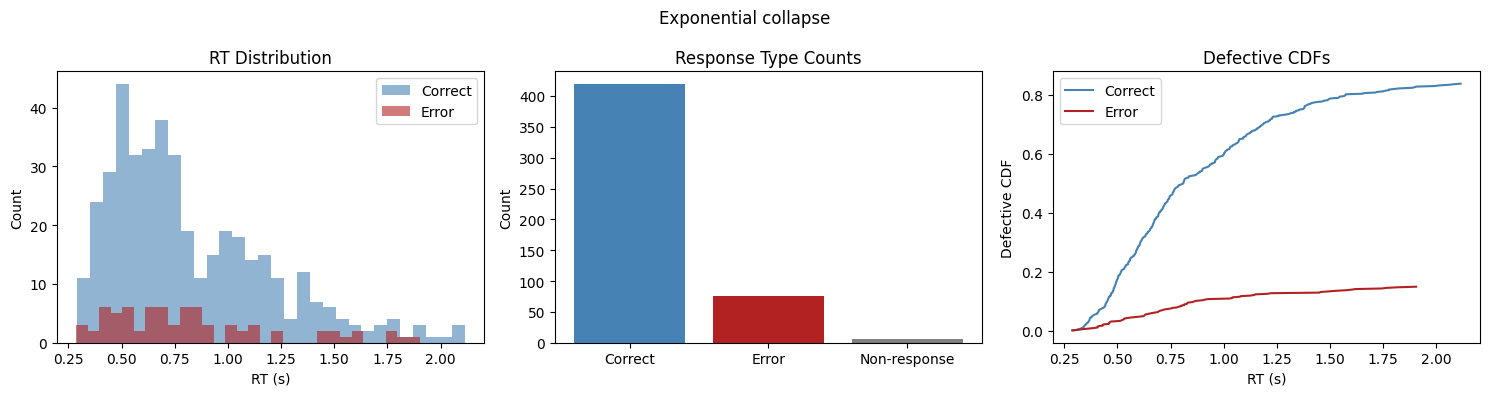

[Exponential collapse] Non-response rate: 1.20%
[Exponential collapse] Accuracy (of responses): 84.82%


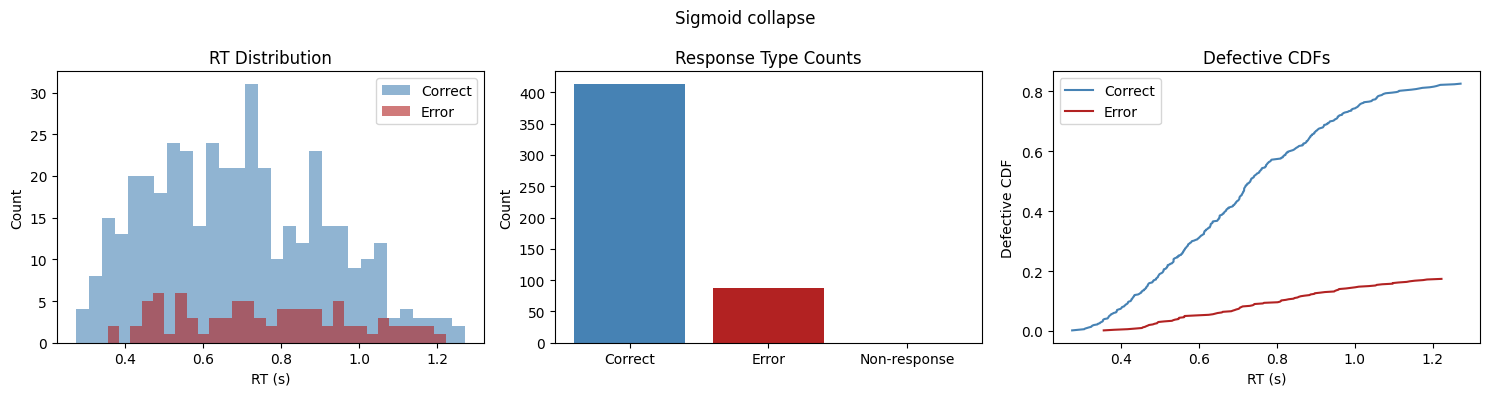

[Sigmoid collapse] Non-response rate: 0.00%
[Sigmoid collapse] Accuracy (of responses): 82.60%


In [22]:
def plot_ddm_results(df, title_prefix=""):
    correct_rts = df.loc[df['choice'] == 1, 'rt'].dropna()
    error_rts   = df.loc[df['choice'] == 0, 'rt'].dropna()
    n_nonresp   = (df['choice'] == -1).sum()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(title_prefix)

    axes[0].hist(correct_rts, bins=30, alpha=0.6, label='Correct', color='steelblue')
    axes[0].hist(error_rts, bins=30, alpha=0.6, label='Error', color='firebrick')
    axes[0].set_xlabel('RT (s)'); axes[0].set_ylabel('Count')
    axes[0].set_title('RT Distribution'); axes[0].legend()

    counts = df['choice'].value_counts().reindex([1, 0, -1], fill_value=0)
    axes[1].bar(['Correct', 'Error', 'Non-response'], counts.values,
                color=['steelblue', 'firebrick', 'gray'])
    axes[1].set_ylabel('Count'); axes[1].set_title('Response Type Counts')

    p_correct = len(correct_rts) / len(df)
    p_error = len(error_rts) / len(df)

    x_c = np.sort(correct_rts); y_c = np.arange(1, len(x_c)+1) / len(x_c) * p_correct
    x_e = np.sort(error_rts);   y_e = np.arange(1, len(x_e)+1) / len(x_e) * p_error

    axes[2].plot(x_c, y_c, color='steelblue', label='Correct')
    axes[2].plot(x_e, y_e, color='firebrick', label='Error')
    axes[2].set_xlabel('RT (s)'); axes[2].set_ylabel('Defective CDF')
    axes[2].set_title('Defective CDFs'); axes[2].legend()

    plt.tight_layout()
    plt.show()

    print(f"[{title_prefix}] Non-response rate: {n_nonresp/len(df):.2%}")
    print(f"[{title_prefix}] Accuracy (of responses): {p_correct/(p_correct+p_error):.2%}")


plot_ddm_results(pd.read_csv('../data/simulated_data_exponential.csv'), "Exponential collapse")
plot_ddm_results(pd.read_csv('../data/simulated_data_sigmoid.csv'), "Sigmoid collapse")

In [23]:


# def simulate_ddm_batch(v, a, t0, z, boundary, dt, n_trials, deadline_step, noise_sd, rng):
#     """
#     Vectorized Euler-Maruyama simulation: all n_trials of ONE condition
#     are simulated together, looping over time steps (not trials).

#     Returns
#     -------
#     rts     : (n_trials,) response time in seconds, NaN = non-response
#     choices : (n_trials,) 1=upper/correct, 0=lower/error, -1=non-response
#     """
#     x = np.full(n_trials, (z - 0.5) * 2 * a, dtype=float)
#     rts = np.full(n_trials, np.nan)
#     choices = np.full(n_trials, -1, dtype=int)
#     active = np.ones(n_trials, dtype=bool)
#     max_steps = len(boundary)

#     for step in range(max_steps):
#         if deadline_step is not None and step >= deadline_step:
#             break 
#         if not active.any():
#             break

#         b = boundary[step]
#         upper_hit = active & (x >= b)
#         lower_hit = active & (x <= -b)

#         rts[upper_hit] = t0 + step * dt
#         choices[upper_hit] = 1
#         rts[lower_hit] = t0 + step * dt
#         choices[lower_hit] = 0
#         active &= ~(upper_hit | lower_hit)

#         x[active] += v * dt + noise_sd * np.sqrt(dt) * rng.standard_normal(active.sum())

#     return rts, choices



In [24]:
# def simulate_full_dataset(
#     n_participants=24,
#     coherences=(0.03, 0.07, 0.11, 0.15, 0.19, 0.23),
#     cues=("speed", "accuracy"),
#     deadline_conditions=("deadline", "no_deadline"),
#     n_trials_per_cell=50,
#     dt=0.002,
#     deadline_time=1.35, # from paper
#     max_time=3.0,
#     noise_sd=1.0,
#     seed=0,
# ):
#     rng = np.random.default_rng(seed)
#     rows = []
#     true_params = []  
 
#     for pp in range(1, n_participants + 1):
#         for cue in cues:
#             for deadline_cond in deadline_conditions:
#                 p = sample_cell_priors(rng)
#                 ddl = deadline_time if deadline_cond == "deadline" else None
 
#                 time_axis = np.arange(int(max_time / dt)) * dt
#                 boundary = exponential_collapse(time_axis, a=p["a"], lam=p["lam"])
#                 deadline_step = int(ddl / dt) if ddl is not None else None
 
#                 for diff_idx, coherence in enumerate(coherences, start=1):
#                     v = p["v_scale"] * coherence + rng.normal(0, 0.3)
 
#                     rts, choices = simulate_ddm_batch(
#                         v=v, a=p["a"], t0=p["t0"], z=0.5,
#                         boundary=boundary, dt=dt,
#                         n_trials=n_trials_per_cell,
#                         deadline_step=deadline_step,
#                         noise_sd=noise_sd, rng=rng,
#                     )
 
#                     for rt, ch in zip(rts, choices):
#                         rows.append({
#                             "difficulty": diff_idx,
#                             "rt": rt,
#                             "acc": np.nan if ch == -1 else int(ch == 1),
#                             "pp": pp,
#                             "deadline": deadline_cond,
#                             "cue": cue,
#                             "coherence": coherence,
#                         })
 
#                 true_params.append({
#                     "pp": pp, "cue": cue, "deadline": deadline_cond,
#                     "v_scale": p["v_scale"], "a": p["a"], "t0": p["t0"], "lam": p["lam"],
#                 })
 
#     df = pd.DataFrame(rows)
#     df.index.name = ""
#     params_df = pd.DataFrame(true_params)
#     return df, params_df

In [25]:
# df, params_df = simulate_full_dataset(n_participants=6, n_trials_per_cell=30)
# df.to_csv("../data/simulated_full_dataset.csv", index=False)
# print(df.head())
# print("\nTrue parameters per cell (first few):")
# print(params_df.head(8))


In [26]:
# def _defective_cdf(rts, correct_mask, n_total):
#     rt_c = rts[correct_mask].dropna()
#     rt_e = rts[~correct_mask & rts.notna()].dropna()
#     p_c, p_e = len(rt_c) / n_total, len(rt_e) / n_total
#     x_c, y_c = np.sort(rt_c), np.arange(1, len(rt_c) + 1) / max(len(rt_c), 1) * p_c
#     x_e, y_e = np.sort(rt_e), np.arange(1, len(rt_e) + 1) / max(len(rt_e), 1) * p_e
#     return (x_c, y_c), (x_e, y_e)


In [27]:
# def plot_insight_summary(df):
#     fig = plt.figure(figsize=(16, 10))
#     gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)

#     colors = {"speed": "#d95f02", "accuracy": "#1b9e77"}
#     linestyles = {"deadline": "-", "no_deadline": "--"}

#     ax1 = fig.add_subplot(gs[0, 0])
#     summary = df.groupby(["cue", "deadline"]).agg(
#         mean_rt=("rt", "mean"), accuracy=("acc", "mean")
#     ).reset_index()
#     labels = [f"{r.cue}\n{r.deadline}" for r in summary.itertuples()]
#     bar_colors = [colors[r.cue] for r in summary.itertuples()]
#     ax1.bar(labels, summary["mean_rt"], color=bar_colors, alpha=0.85)
#     ax1.set_ylabel("Mean RT (s)")
#     ax1.set_title("Mean RT by condition\n(deadlines & speed-cue -> faster)")

#     ax2 = fig.add_subplot(gs[0, 1])
#     ax2.bar(labels, summary["accuracy"], color=bar_colors, alpha=0.85)
#     ax2.set_ylabel("Accuracy")
#     ax2.set_ylim(0, 1)
#     ax2.set_title("Accuracy by condition\n(deadlines & speed-cue -> lower accuracy)")

#     ax3 = fig.add_subplot(gs[0, 2])
#     psych = df.groupby(["cue", "deadline", "coherence"]).agg(
#         accuracy=("acc", "mean")
#     ).reset_index()
#     for cue in colors:
#         for dl in linestyles:
#             sub = psych[(psych.cue == cue) & (psych.deadline == dl)].sort_values("coherence")
#             ax3.plot(sub.coherence, sub.accuracy, marker="o",
#                      color=colors[cue], linestyle=linestyles[dl],
#                      label=f"{cue}, {dl}")
#     ax3.set_xlabel("Coherence")
#     ax3.set_ylabel("Accuracy")
#     ax3.set_title("Psychometric function\n(difficulty effect, separate from cue/deadline)")
#     ax3.legend(fontsize=7, loc="lower right")

#     ax4 = fig.add_subplot(gs[1, 0])
#     chrono = df.groupby(["cue", "deadline", "coherence"]).agg(
#         mean_rt=("rt", "mean")
#     ).reset_index()
#     for cue in colors:
#         for dl in linestyles:
#             sub = chrono[(chrono.cue == cue) & (chrono.deadline == dl)].sort_values("coherence")
#             ax4.plot(sub.coherence, sub.mean_rt, marker="o",
#                      color=colors[cue], linestyle=linestyles[dl],
#                      label=f"{cue}, {dl}")
#     ax4.set_xlabel("Coherence")
#     ax4.set_ylabel("Mean RT (s)")
#     ax4.set_title("Chronometric function")
#     ax4.legend(fontsize=7, loc="upper right")

#     ax5 = fig.add_subplot(gs[1, 1])
#     n_total_dl = len(df[df.deadline == "deadline"])
#     n_total_nodl = len(df[df.deadline == "no_deadline"])
#     (xc, yc), (xe, ye) = _defective_cdf(
#         df.loc[df.deadline == "deadline", "rt"],
#         df.loc[df.deadline == "deadline", "acc"] == 1,
#         n_total_dl,
#     )
#     ax5.plot(xc, yc, color="steelblue", label="correct, deadline")
#     ax5.plot(xe, ye, color="steelblue", linestyle="--", label="error, deadline")
#     (xc2, yc2), (xe2, ye2) = _defective_cdf(
#         df.loc[df.deadline == "no_deadline", "rt"],
#         df.loc[df.deadline == "no_deadline", "acc"] == 1,
#         n_total_nodl,
#     )
#     ax5.plot(xc2, yc2, color="firebrick", label="correct, no deadline")
#     ax5.plot(xe2, ye2, color="firebrick", linestyle="--", label="error, no deadline")
#     ax5.set_xlabel("RT (s)")
#     ax5.set_ylabel("Defective CDF")
#     ax5.set_title("Slow-errors signature:\nerror curve shape, deadline vs not")
#     ax5.legend(fontsize=7)



#     plt.suptitle("Simulated SAT dataset: cue & deadline effects", fontsize=14, y=1.02)
#     plt.tight_layout()
#     plt.show()








In [28]:
# df = pd.read_csv("../data/simulated_full_dataset.csv", index_col=0)
# plot_insight_summary(df)